MOBILE DATASET
   RAM  Battery_Power  Internal_Memory  Screen_Size  Price_Range
0    2           2500               16          5.0            0
1    2           3000               32          5.2            0
2    3           2800               32          5.5            0
3    3           3500               64          5.8            1
4    4           3200               64          6.0            1

ACTUAL PRICE RANGES:
[0, 1, 3, 3, 2]

PREDICTED PRICE RANGES:
[0, 1, 3, 3, 2]

Model Accuracy: 100.0 %


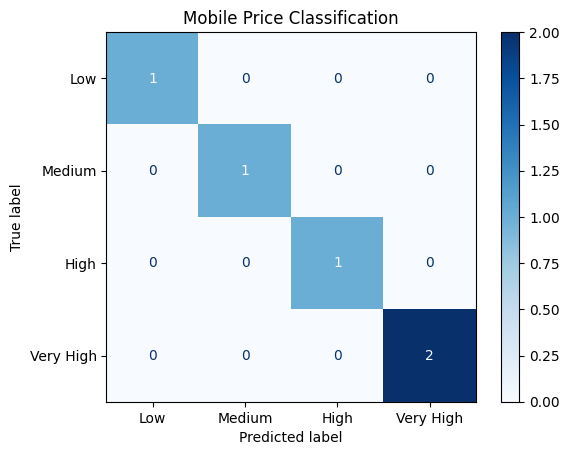


CLASSIFICATION REPORT:
              precision    recall  f1-score   support

         Low       1.00      1.00      1.00         1
      Medium       1.00      1.00      1.00         1
        High       1.00      1.00      1.00         1
   Very High       1.00      1.00      1.00         2

    accuracy                           1.00         5
   macro avg       1.00      1.00      1.00         5
weighted avg       1.00      1.00      1.00         5


NEW MOBILE PREDICTION
RAM: 8 GB
Battery: 4500 mAh
Internal Memory: 256 GB
Screen Size: 6.5 inches
Predicted Price Range: Very High Price

Program executed successfully!


In [18]:

# Mobile Price Prediction Using Decision Tree Classifier

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# Step 1: Create a sample mobile dataset
data = {
    "RAM": [
        2, 2, 3, 3, 4, 4, 6, 6, 8, 8,
        12, 12, 3, 4, 6, 8, 12, 2, 6, 8
    ],
    "Battery_Power": [
        2500, 3000, 2800, 3500, 3200,
        4000, 3500, 4500, 4000, 5000,
        4500, 5000, 3000, 3500, 4000,
        4500, 5000, 2600, 4200, 4800
    ],
    "Internal_Memory": [
        16, 32, 32, 64, 64, 64, 128, 128, 128, 256,
        256, 512, 32, 64, 128, 256, 512, 16, 128, 256
    ],
    "Screen_Size": [
        5.0, 5.2, 5.5, 5.8, 6.0,
        6.1, 6.2, 6.3, 6.5, 6.6,
        6.7, 6.8, 5.4, 5.9, 6.2,
        6.5, 6.8, 5.0, 6.3, 6.6
    ],
    "Price_Range": [
        0, 0, 0, 1, 1, 1, 2, 2, 2, 3,
        3, 3, 0, 1, 2, 3, 3, 0, 2, 3
    ]
}

df = pd.DataFrame(data)

print("MOBILE DATASET")
print(df.head())

# Step 2: Separate features and target
X = df[[
    "RAM", "Battery_Power",
    "Internal_Memory", "Screen_Size"
]]
y = df["Price_Range"]

# Step 3: Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25,
    random_state=42, stratify=y
)

# Step 4: Train the Decision Tree model
model = DecisionTreeClassifier(random_state=42)
model.fit(X_train, y_train)

# Step 5: Predict price ranges
y_pred = model.predict(X_test)

print("\nACTUAL PRICE RANGES:")
print(y_test.tolist())

print("\nPREDICTED PRICE RANGES:")
print(y_pred.tolist())

# Step 6: Evaluate model accuracy
accuracy = accuracy_score(y_test, y_pred)
print("\nModel Accuracy:", round(accuracy * 100, 2), "%")

# Step 7: Display confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1, 2, 3])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Low", "Medium", "High", "Very High"]
)
disp.plot(cmap="Blues")
plt.title("Mobile Price Classification")
plt.show()

# Step 8: Classification report
print("\nCLASSIFICATION REPORT:")
print(classification_report(
    y_test, y_pred,
    labels=[0, 1, 2, 3],
    target_names=["Low", "Medium", "High", "Very High"],
    zero_division=0
))

# Step 9: Predict the price range of a new mobile
new_mobile = pd.DataFrame({
    "RAM": [8],
    "Battery_Power": [4500],
    "Internal_Memory": [256],
    "Screen_Size": [6.5]
})

prediction = model.predict(new_mobile)[0]

price_labels = {
    0: "Low Price",
    1: "Medium Price",
    2: "High Price",
    3: "Very High Price"
}

print("\nNEW MOBILE PREDICTION")
print("RAM: 8 GB")
print("Battery: 4500 mAh")
print("Internal Memory: 256 GB")
print("Screen Size: 6.5 inches")
print("Predicted Price Range:", price_labels[prediction])

print("\nProgram executed successfully!")
